Since we completed 1CCCV charge protocol now let's charge with 1CPCV.
First, we need to define what is the value of 1P.
1P = Vnominal * 1C
I could not find any Vonimal parameter in the Chen2020. So I will take Vnominal as 3.6V this specific cell.

In [129]:
import pybamm
import matplotlib.pyplot as plt
import numpy as np

In [130]:
parameter_values = pybamm.ParameterValues("Chen2020") #Importing parameter values from the parameter set
parameter_values.set_initial_state(0); # Set initial state of charge to 0%
initial_soc = 0;

In [131]:
V_nom = 3.6 # Nominal voltage of the cell
Q_nom = parameter_values["Nominal cell capacity [A.h]"]
P_1P = V_nom * Q_nom # Nominal power of the cell
print("Nominal power of the cell: ", P_1P, "W")

Nominal power of the cell:  18.0 W


In [132]:
CPCV_Charging = pybamm.Experiment([
    f"Charge at {P_1P} W until 4.2 V",
     "Hold at 4.2 V until C/20"])


In [133]:
model = pybamm.lithium_ion.DFN() # Create a DFN model
sim = pybamm.Simulation(model, experiment=CPCV_Charging,parameter_values=parameter_values)
sol = sim.solve() # Solve the simulation

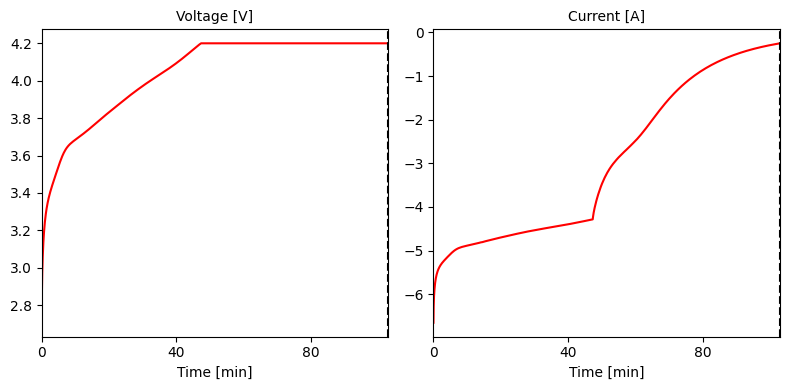

In [134]:
qp = pybamm.QuickPlot(sol,output_variables=["Voltage [V]", "Current [A]",], time_unit="minutes")
qp.plot(qp.max_t) # Plot the voltage and current over time for the entire experiment

In [135]:
t   = sol["Time [min]"].entries
soc = (initial_soc - sol["Discharge capacity [A.h]"].entries / Q_nom) * 100
t_switch   = sol.cycles[0]["Time [min]"].entries[-1]
soc_switch = np.interp(t_switch, t, soc) 


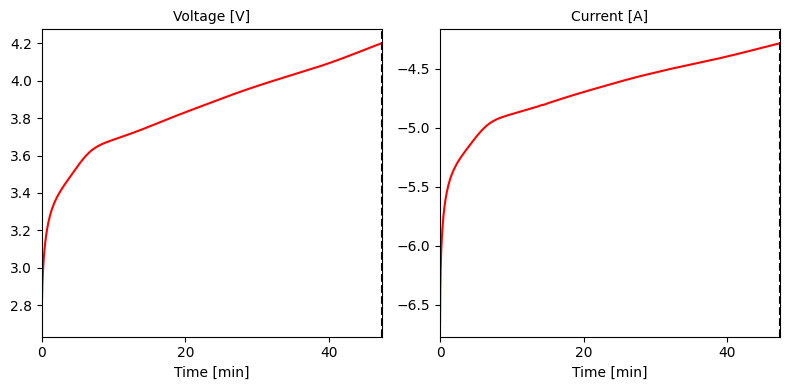

In [136]:
CP_Phase = sim.solution.cycles[0] # Get the constant power phase of the charging cycle with 18W
qp_CP = pybamm.QuickPlot(CP_Phase,output_variables=["Voltage [V]", "Current [A]"], time_unit="minutes")
qp_CP.plot(qp_CP.max_t) # Plot the voltage and current over time for the constant power

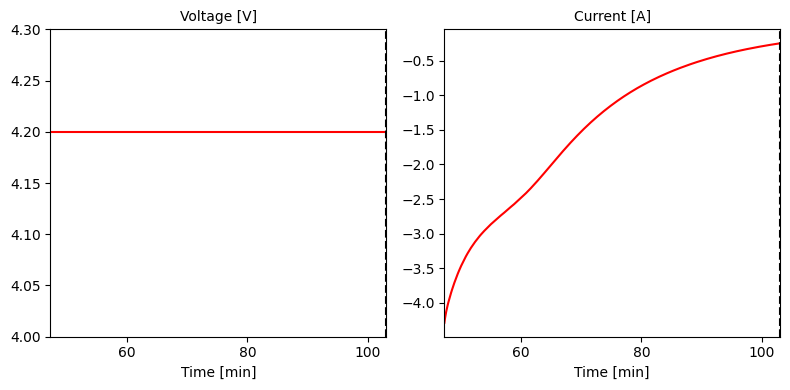

In [137]:
CV_Phase = sim.solution.cycles[1] # Get the constant voltage phase of the charging cycle with 4.2V
qp_CV = pybamm.QuickPlot(CV_Phase,output_variables=["Voltage [V]", "Current [A]"], time_unit="minutes", variable_limits={"Voltage [V]": (4.0, 4.3)})
qp_CV.plot(qp_CV.max_t) # Plot the voltage and current over time for the constant voltage with 4.2V

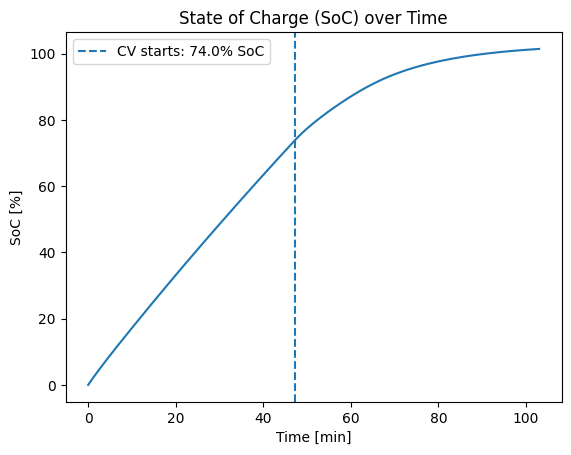

In [138]:
plt.plot(t, soc)
plt.axvline(t_switch, linestyle="--", label=f"CV starts: {soc_switch:.1f}% SoC")
plt.xlabel("Time [min]"); plt.ylabel("SoC [%]"); plt.legend()
plt.title("State of Charge (SoC) over Time")
plt.show()